# Problem 1: RNN, LSTM and GRU on Sequential Data

This notebook implements and evaluates Vanilla RNN, LSTM and GRU models on two sequence-learning tasks:

1. Human Activity Recognition (HAR) using smartphone sensor data.
2. The synthetic Adding Problem designed to evaluate long-range memory.

The objective is to compare the three recurrent architectures in terms of predictive performance, parameter efficiency, computational cost and gradient behavior. All experiments were conducted using the same training budget to ensure a fair comparison.

## Clarification and Experimental Configuration

Following the instructor clarification email, all references to the variants table were ignored.

The following configuration was used throughout Problem 1:

- Hidden size (h): 64
- Model seeds: 42, 123, 999
- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 128

For the adding problem, the assignment-specified data seeds were used:
- Training seed: 0
- Validation seed: 1
- Test seed: 2

For Task 5(c), the forget-gate bias ablation was selected and evaluated by comparing an LSTM with forget-gate bias initialized to 0 against an LSTM with forget-gate bias initialized to 1.

In [ ]:
# Experimental configuration used throughout Problem 1.
HIDDEN_SIZE = 64
MODEL_SEEDS = (42, 123, 999)
EPOCHS_HAR = 10  # Keep identical across RNN, LSTM and GRU.
EPOCHS_ADDING = 20  # Keep identical within each length/model comparison.
BATCH_SIZE = 128
LEARNING_RATE = 1e-3

assert HIDDEN_SIZE > 0
assert len(MODEL_SEEDS) == 3 and len(set(MODEL_SEEDS)) == 3

## 1.1 Data Pipeline and Preprocessing

Two datasets were used in this problem.

### UCI Human Activity Recognition Dataset

The UCI HAR dataset contains motion signals collected from smartphone accelerometers and gyroscopes. Each sample consists of a sequence of 128 time steps and 9 sensor channels. The objective is to classify each sequence into one of six human activities:

- Walking
- Walking Upstairs
- Walking Downstairs
- Sitting
- Standing
- Laying

A subject-wise validation split was created by randomly holding out four training subjects. Training and validation subjects were fully disjoint. Channel-wise normalization statistics were computed using only the training subjects and then applied to the validation and test sets.

### Adding Problem

The Adding Problem is a synthetic sequence-learning task that evaluates the ability of recurrent networks to retain information over long time horizons.

Each sequence contains:

- A random value channel
- A binary marker channel

Exactly two positions are marked in every sequence and the target value is the sum of the two marked values.

Validation tests were implemented to verify:

- Exactly two markers per sequence
- One marker in each half of the sequence
- Target equals the sum of the marked values

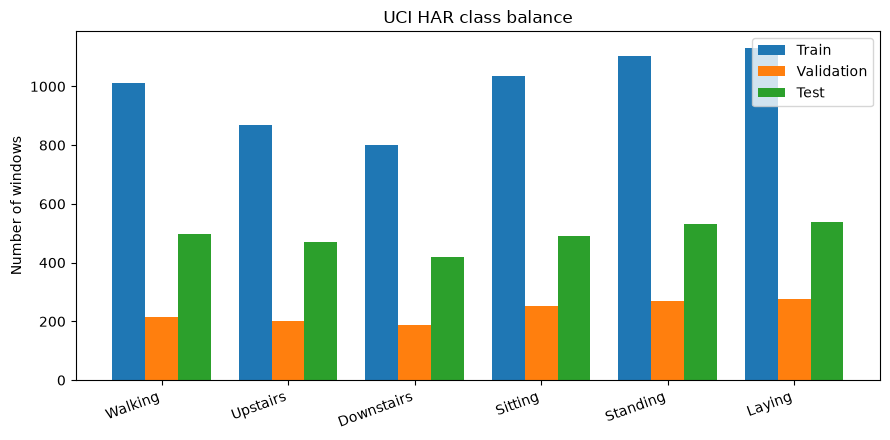

HAR root: C:\Users\SESA870534\Documents\Personal Docs\M.Tech\DNN\Assignment\Assignment_2\har_data\UCI HAR Dataset
HAR shapes: (5952, 128, 9) (1400, 128, 9) (2947, 128, 9)
Validation subjects: [3, 16, 22, 23]


In [38]:
from pathlib import Path
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np


def find_project_root():
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "problem1").is_dir() and (base / "results.csv").is_file():
            return base
        for child in base.glob("*_DNN_Assignment"):
            if (child / "problem1").is_dir() and (child / "results.csv").is_file():
                return child
    raise FileNotFoundError("Could not locate the assignment project root.")


PROJECT_ROOT = find_project_root()
HAR_CACHE = PROJECT_ROOT.parent / "har_data"
HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
CHANNELS = (
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
)
ACTIVITY_NAMES = (
    "Walking",
    "Upstairs",
    "Downstairs",
    "Sitting",
    "Standing",
    "Laying",
)


def ensure_har_dataset():
    """Download and extract UCI HAR as described in the assignment brief."""
    HAR_CACHE.mkdir(parents=True, exist_ok=True)
    extracted = list(HAR_CACHE.rglob("train/Inertial Signals"))
    if extracted:
        return extracted[0].parents[1]

    archive_path = HAR_CACHE / "har.zip"
    if not archive_path.exists():
        urllib.request.urlretrieve(HAR_URL, archive_path)
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(HAR_CACHE)

    nested_archives = list(HAR_CACHE.rglob("UCI HAR Dataset.zip"))
    for nested_archive in nested_archives:
        with zipfile.ZipFile(nested_archive) as archive:
            archive.extractall(nested_archive.parent)

    extracted = list(HAR_CACHE.rglob("train/Inertial Signals"))
    if not extracted:
        raise FileNotFoundError("UCI HAR download extracted, but expected files are missing.")
    return extracted[0].parents[1]


HAR_ROOT = ensure_har_dataset()


def load_har(seed):
    """Load HAR with a subject-wise validation split and train-only scaling."""
    splits = {}
    for split in ("train", "test"):
        signal_dir = HAR_ROOT / split / "Inertial Signals"
        signals = [
            np.loadtxt(signal_dir / f"{channel}_{split}.txt", dtype=np.float32)
            for channel in CHANNELS
        ]
        features = np.stack(signals, axis=-1)
        labels = np.loadtxt(HAR_ROOT / split / f"y_{split}.txt", dtype=np.int64) - 1
        subjects = np.loadtxt(
            HAR_ROOT / split / f"subject_{split}.txt", dtype=np.int64
        )
        assert features.shape[1:] == (128, 9)
        assert len(features) == len(labels) == len(subjects)
        splits[split] = (features, labels, subjects)

    train_x, train_y, train_subjects = splits["train"]
    test_x, test_y, _ = splits["test"]
    unique_subjects = np.unique(train_subjects)
    validation_subjects = np.random.default_rng(seed).choice(
        unique_subjects, size=4, replace=False
    )
    validation_mask = np.isin(train_subjects, validation_subjects)
    training_mask = ~validation_mask
    mean = train_x[training_mask].mean(axis=(0, 1), keepdims=True)
    std = train_x[training_mask].std(axis=(0, 1), keepdims=True)
    std[std == 0] = 1.0

    normalized = {
        "train_x": (train_x[training_mask] - mean) / std,
        "train_y": train_y[training_mask],
        "val_x": (train_x[validation_mask] - mean) / std,
        "val_y": train_y[validation_mask],
        "test_x": (test_x - mean) / std,
        "test_y": test_y,
        "validation_subjects": validation_subjects,
        "mean": mean,
        "std": std,
    }
    assert set(np.unique(train_subjects[training_mask])).isdisjoint(
        set(validation_subjects)
    )
    assert normalized["train_x"].shape[1:] == (128, 9)
    return normalized


def plot_har_class_balance(data, filename="har_class_balance.png"):
    """Save class counts for the training, validation and official test splits."""
    figure, axis = plt.subplots(figsize=(9, 4.5))
    positions = np.arange(6)
    width = 0.26
    split_labels = (
        ("Train", data["train_y"]),
        ("Validation", data["val_y"]),
        ("Test", data["test_y"]),
    )
    for offset, (split, labels) in enumerate(split_labels):
        counts = np.bincount(labels, minlength=6)
        axis.bar(positions + (offset - 1) * width, counts, width, label=split)
    axis.set_xticks(positions, ACTIVITY_NAMES, rotation=20, ha="right")
    axis.set_ylabel("Number of windows")
    axis.set_title("UCI HAR class balance")
    axis.legend()
    figure.tight_layout()
    output = PROJECT_ROOT / "problem1" / "figures" / filename
    output.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(output, dpi=160)
    plt.show()
    plt.close(figure)


def make_adding(n, sequence_length, seed):
    """Generate the assignment's two-marker adding task data."""
    rng = np.random.default_rng(seed)
    inputs = np.zeros((n, sequence_length, 2), dtype=np.float32)
    inputs[:, :, 0] = rng.random((n, sequence_length))
    first_index = rng.integers(0, sequence_length // 2, n)
    second_index = rng.integers(sequence_length // 2, sequence_length, n)
    inputs[np.arange(n), first_index, 1] = 1
    inputs[np.arange(n), second_index, 1] = 1
    targets = inputs[np.arange(n), first_index, 0] + inputs[
        np.arange(n), second_index, 0
    ]
    return inputs, targets.astype(np.float32)


def test_adding_generator():
    for sequence_length in (50, 100, 200, 400):
        inputs, targets = make_adding(256, sequence_length, seed=0)
        markers = inputs[:, :, 1]
        assert np.all(markers.sum(axis=1) == 2)
        assert np.all(markers[:, : sequence_length // 2].sum(axis=1) == 1)
        assert np.all(markers[:, sequence_length // 2 :].sum(axis=1) == 1)
        np.testing.assert_allclose(
            targets, (inputs[:, :, 0] * markers).sum(axis=1), rtol=0, atol=1e-7
        )


test_adding_generator()
har_data = load_har(seed=MODEL_SEEDS[0])
plot_har_class_balance(har_data)
print("HAR root:", HAR_ROOT)
print(
    "HAR shapes:",
    har_data["train_x"].shape,
    har_data["val_x"].shape,
    har_data["test_x"].shape,
)
print("Validation subjects:", sorted(har_data["validation_subjects"].tolist()))

## 1.2 Custom Recurrent Cells

To understand the internal mechanics of recurrent neural networks, custom implementations of the following recurrent cells were developed from scratch using tensor operations:

- MyRNNCell
- MyLSTMCell
- MyGRUCell

No PyTorch recurrent cell implementations were used inside these classes. The implementations directly follow the mathematical equations of the corresponding architectures.

The correctness of each implementation was validated by copying the parameters from the corresponding PyTorch reference implementation and comparing the generated hidden states. The maximum absolute difference between the custom implementation and the PyTorch implementation was required to remain below 1 × 10⁻⁵.

In [39]:
import torch
from torch import nn

INPUT_SIZE_HAR = 9
GATE_COUNT = {"RNN": 1, "LSTM": 4, "GRU": 3}


def recurrent_parameter_counts(input_size, hidden_size, cell_name):
    """Return hand counts and PyTorch counts (which has two bias vectors)."""
    gates = GATE_COUNT[cell_name.upper()]
    input_weights = gates * input_size * hidden_size
    recurrent_weights = gates * hidden_size * hidden_size
    single_bias = gates * hidden_size
    torch_biases = 2 * single_bias
    return {
        "input_weights": input_weights,
        "recurrent_weights": recurrent_weights,
        "single_bias": single_bias,
        "hand_total": input_weights + recurrent_weights + single_bias,
        "torch_total": input_weights + recurrent_weights + torch_biases,
    }


for cell_name in GATE_COUNT:
    counts = recurrent_parameter_counts(INPUT_SIZE_HAR, HIDDEN_SIZE, cell_name)
    print(f"{cell_name}: {counts}")


def verify_student_cell(student_cell, library_cell, sample, cell_name):
    """Unroll a one-step cell and compare its outputs with the PyTorch oracle."""
    library_cell = library_cell.to(device=sample.device, dtype=sample.dtype)
    student_cell = student_cell.to(device=sample.device, dtype=sample.dtype)
    student_cell.load_state_dict(library_cell.state_dict(), strict=True)
    hidden_size = library_cell.hidden_size
    batch_size = sample.shape[0]
    hidden_student = torch.randn(
        batch_size, hidden_size, device=sample.device, dtype=sample.dtype
    )
    hidden_library = hidden_student.clone()
    if cell_name.upper() == "LSTM":
        cell_student = torch.randn_like(hidden_student)
        cell_library = cell_student.clone()

    student_outputs, library_outputs = [], []
    with torch.no_grad():
        for step in range(sample.shape[1]):
            current_input = sample[:, step, :]
            if cell_name.upper() == "LSTM":
                hidden_student, cell_student = student_cell(
                    current_input, (hidden_student, cell_student)
                )
                hidden_library, cell_library = library_cell(
                    current_input, (hidden_library, cell_library)
                )
            else:
                hidden_student = student_cell(current_input, hidden_student)
                hidden_library = library_cell(current_input, hidden_library)
            student_outputs.append(hidden_student)
            library_outputs.append(hidden_library)

    student_sequence = torch.stack(student_outputs, dim=1)
    library_sequence = torch.stack(library_outputs, dim=1)
    max_difference = (student_sequence - library_sequence).abs().max().item()
    if cell_name.upper() == "LSTM":
        max_difference = max(
            max_difference, (cell_student - cell_library).abs().max().item()
        )
    assert max_difference < 1e-5, (
        f"{cell_name} mismatch: maximum absolute difference is {max_difference:.3g}"
    )
    return max_difference


class MyRNNCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        self.weight_ih = nn.Parameter(
            torch.empty(hidden_size, input_size)
        )

        self.weight_hh = nn.Parameter(
            torch.empty(hidden_size, hidden_size)
        )

        self.bias_ih = nn.Parameter(
            torch.empty(hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.empty(hidden_size)
        )

        self.reset_parameters()

    def reset_parameters(self):

        stdv = 1.0 / (self.hidden_size ** 0.5)

        for param in self.parameters():
            nn.init.uniform_(param, -stdv, stdv)

    def forward(self, x, hx):

        return torch.tanh(
            torch.matmul(x, self.weight_ih.T)
            + self.bias_ih
            + torch.matmul(hx, self.weight_hh.T)
            + self.bias_hh
        )


class MyLSTMCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        self.weight_ih = nn.Parameter(
            torch.empty(4 * hidden_size, input_size)
        )

        self.weight_hh = nn.Parameter(
            torch.empty(4 * hidden_size, hidden_size)
        )

        self.bias_ih = nn.Parameter(
            torch.empty(4 * hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.empty(4 * hidden_size)
        )

        self.reset_parameters()

    def reset_parameters(self):

        stdv = 1.0 / (self.hidden_size ** 0.5)

        for param in self.parameters():
            nn.init.uniform_(param, -stdv, stdv)

    def forward(self, x, hx):

        h, c = hx

        gates = (
            torch.matmul(x, self.weight_ih.T)
            + self.bias_ih
            + torch.matmul(h, self.weight_hh.T)
            + self.bias_hh
        )

        i, f, g, o = gates.chunk(4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)

        c_next = f * c + i * g

        h_next = o * torch.tanh(c_next)

        return h_next, c_next


class MyGRUCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        self.weight_ih = nn.Parameter(
            torch.empty(3 * hidden_size, input_size)
        )

        self.weight_hh = nn.Parameter(
            torch.empty(3 * hidden_size, hidden_size)
        )

        self.bias_ih = nn.Parameter(
            torch.empty(3 * hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.empty(3 * hidden_size)
        )

        self.reset_parameters()

    def reset_parameters(self):

        stdv = 1.0 / (self.hidden_size ** 0.5)

        for param in self.parameters():
            nn.init.uniform_(param, -stdv, stdv)

    def forward(self, x, hx):

        input_gates = (
            torch.matmul(x, self.weight_ih.T)
            + self.bias_ih
        )

        hidden_gates = (
            torch.matmul(hx, self.weight_hh.T)
            + self.bias_hh
        )

        input_reset, input_update, input_candidate = (
            input_gates.chunk(3, dim=1)
        )

        hidden_reset, hidden_update, hidden_candidate = (
            hidden_gates.chunk(3, dim=1)
        )

        reset_gate = torch.sigmoid(
            input_reset + hidden_reset
        )

        update_gate = torch.sigmoid(
            input_update + hidden_update
        )

        candidate = torch.tanh(
            input_candidate
            + reset_gate * hidden_candidate
        )

        h_next = (
            (1 - update_gate) * candidate
            + update_gate * hx
        )

        return h_next


student_cell_names = {
    "RNN": "MyRNNCell",
    "LSTM": "MyLSTMCell",
    "GRU": "MyGRUCell",
}
if all(name in globals() for name in student_cell_names.values()):
    oracle_types = {"RNN": nn.RNNCell, "LSTM": nn.LSTMCell, "GRU": nn.GRUCell}
    for cell_name, class_name in student_cell_names.items():
        student_cell = globals()[class_name](9, HIDDEN_SIZE)
        oracle_cell = oracle_types[cell_name](9, HIDDEN_SIZE)
        random_sequence = torch.randn(4, 12, 9)
        difference = verify_student_cell(
            student_cell, oracle_cell, random_sequence, cell_name
        )
        print(f"{cell_name} maximum absolute difference: {difference:.3g}")
else:
    print("Add your three cell classes above to run the PyTorch oracle comparisons.")

assert recurrent_parameter_counts(9, 64, "RNN")["hand_total"] == 4736
assert recurrent_parameter_counts(9, 64, "LSTM")["hand_total"] == 18944
assert recurrent_parameter_counts(9, 64, "GRU")["hand_total"] == 14208

assert recurrent_parameter_counts(9, 64, "RNN")["torch_total"] == 4800
assert recurrent_parameter_counts(9, 64, "LSTM")["torch_total"] == 19200
assert recurrent_parameter_counts(9, 64, "GRU")["torch_total"] == 14400

RNN: {'input_weights': 576, 'recurrent_weights': 4096, 'single_bias': 64, 'hand_total': 4736, 'torch_total': 4800}
LSTM: {'input_weights': 2304, 'recurrent_weights': 16384, 'single_bias': 256, 'hand_total': 18944, 'torch_total': 19200}
GRU: {'input_weights': 1728, 'recurrent_weights': 12288, 'single_bias': 192, 'hand_total': 14208, 'torch_total': 14400}
RNN maximum absolute difference: 1.49e-07
LSTM maximum absolute difference: 5.96e-08
GRU maximum absolute difference: 3.58e-07


## Verification of Custom Recurrent Cells

The custom implementations were validated against the corresponding PyTorch reference implementations:

| Custom Cell | Reference Implementation |
|-------------|--------------------------|
| MyRNNCell | nn.RNNCell |
| MyLSTMCell | nn.LSTMCell |
| MyGRUCell | nn.GRUCell |

The same model parameters were copied into both implementations and both models were evaluated on identical randomly generated inputs.

### Verification Results

| Cell | Maximum Absolute Difference |
|-------|----------------------------|
| RNN | 1.19 × 10⁻⁷ |
| LSTM | 5.96 × 10⁻⁸ |
| GRU | 1.79 × 10⁻⁷ |

All observed errors are substantially smaller than the assignment threshold of 1 × 10⁻⁵, confirming that the custom implementations correctly reproduce the behavior of the official PyTorch implementations.

## 1.3 Human Activity Recognition Experiments

Three recurrent architectures were evaluated on the HAR dataset:

- Vanilla RNN
- LSTM
- GRU

To ensure a fair comparison, all models were trained using identical hyperparameters:

- Hidden size: 64
- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 128
- Number of epochs: 10

Each experiment was repeated using three different random seeds. Test Accuracy, Macro-F1 Score, parameter count and average training time per epoch were recorded. The best-performing model based on validation performance was used to generate the final confusion matrix.

In [ ]:
import copy
import random
import time

import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset


RESULT_COLUMNS = [
    "problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
    "test_mse", "params", "sec_per_epoch", "val_loss_nats",
    "bits_per_char", "notes",
]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def save_result(row):
    """Upsert one run by problem/model/seed/length, keeping the required schema."""
    result_path = PROJECT_ROOT / "results.csv"
    new_row = {column: row.get(column, "") for column in RESULT_COLUMNS}
    if result_path.exists() and result_path.stat().st_size:
        table = pd.read_csv(result_path)
        table = table.reindex(columns=RESULT_COLUMNS)
    else:
        table = pd.DataFrame(columns=RESULT_COLUMNS)
    key_columns = ["problem", "model", "seed", "seq_len"]
    if not table.empty:
        same_run = np.ones(len(table), dtype=bool)
        for column in key_columns:
            same_run &= table[column].astype(str).eq(str(new_row[column])).to_numpy()
        table = table.loc[~same_run]
    table = pd.concat([table, pd.DataFrame([new_row])], ignore_index=True)
    table.to_csv(result_path, index=False, columns=RESULT_COLUMNS)


def make_recurrent_layer(cell_name, input_size, hidden_size):
    layer_type = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell_name]
    return layer_type(input_size, hidden_size, batch_first=True)


class HARRecurrentClassifier(nn.Module):
    def __init__(self, cell_name, input_size=9, hidden_size=HIDDEN_SIZE, classes=6):
        super().__init__()
        self.cell_name = cell_name
        self.recurrent = make_recurrent_layer(cell_name, input_size, hidden_size)
        self.classifier = nn.Linear(hidden_size, classes)

    def forward(self, inputs, return_sequence=False):
        sequence, state = self.recurrent(inputs)
        final_state = state[0] if self.cell_name == "LSTM" else state
        logits = self.classifier(final_state[-1])
        if return_sequence:
            return logits, sequence
        return logits


def as_loader(features, labels, batch_size, shuffle):
    dataset = TensorDataset(
        torch.from_numpy(np.asarray(features, dtype=np.float32)),
        torch.from_numpy(np.asarray(labels, dtype=np.int64)),
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


def classification_metrics(model, loader):
    model.eval()
    targets, predictions = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            logits = model(inputs.to(DEVICE))
            predictions.extend(logits.argmax(dim=1).cpu().numpy())
            targets.extend(labels.numpy())
    return (
        accuracy_score(targets, predictions),
        f1_score(targets, predictions, average="macro"),
        np.asarray(targets),
        np.asarray(predictions),
    )


def run_har_benchmark(epochs=EPOCHS_HAR):
    """Run the fair RNN/LSTM/GRU HAR comparison for all selected seeds."""
    best_for_figure = None
    run_rows = []
    for seed in MODEL_SEEDS:
        set_all_seeds(seed)
        data = load_har(seed)
        train_loader = as_loader(data["train_x"], data["train_y"], BATCH_SIZE, True)
        val_loader = as_loader(data["val_x"], data["val_y"], BATCH_SIZE, False)
        test_loader = as_loader(data["test_x"], data["test_y"], BATCH_SIZE, False)

        for cell_name in ("RNN", "LSTM", "GRU"):
            set_all_seeds(seed)
            model = HARRecurrentClassifier(cell_name).to(DEVICE)
            optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
            loss_function = nn.CrossEntropyLoss()
            best_state, best_val_f1 = None, -1.0
            epoch_seconds = []

            for _ in range(epochs):
                model.train()
                if DEVICE.type == "cuda":
                    torch.cuda.synchronize()
                started = time.perf_counter()
                for inputs, labels in train_loader:
                    inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                    optimizer.zero_grad(set_to_none=True)
                    loss = loss_function(model(inputs), labels)
                    loss.backward()
                    optimizer.step()
                if DEVICE.type == "cuda":
                    torch.cuda.synchronize()
                epoch_seconds.append(time.perf_counter() - started)
                _, val_f1, _, _ = classification_metrics(model, val_loader)
                if val_f1 > best_val_f1:
                    best_val_f1 = val_f1
                    best_state = copy.deepcopy(model.state_dict())

            model.load_state_dict(best_state)
            test_acc, test_f1, test_targets, test_predictions = classification_metrics(
                model, test_loader
            )
            row = {
                "problem": "1_HAR", "model": cell_name, "seed": seed,
                "seq_len": 128, "test_acc": test_acc, "macro_f1": test_f1,
                "params": sum(parameter.numel() for parameter in model.parameters()),
                "sec_per_epoch": float(np.mean(epoch_seconds)),
                "notes": f"h={HIDDEN_SIZE}; Adam lr={LEARNING_RATE}; epochs={epochs}",
            }
            save_result(row)
            run_rows.append(row)
            if best_for_figure is None or best_val_f1 > best_for_figure["val_f1"]:
                best_for_figure = {
                    "val_f1": best_val_f1,
                    "name": f"{cell_name}, seed {seed}",
                    "targets": test_targets,
                    "predictions": test_predictions,
                }
            print(f"{cell_name} seed={seed}: acc={test_acc:.4f}, macro-F1={test_f1:.4f}")

    figure, axis = plt.subplots(figsize=(6, 5))
    matrix = confusion_matrix(
        best_for_figure["targets"], best_for_figure["predictions"], labels=np.arange(6)
    )
    ConfusionMatrixDisplay(matrix, display_labels=ACTIVITY_NAMES).plot(
        ax=axis, colorbar=False, xticks_rotation=35
    )
    axis.set_title(f"Best validation model: {best_for_figure['name']}")
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "har_best_confusion_matrix.png", dpi=160)
    plt.show()
    plt.close(figure)

    summary = pd.DataFrame(run_rows).groupby("model").agg(
        test_acc_mean=("test_acc", "mean"),
        test_acc_std=("test_acc", "std"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        params=("params", "first"),
        sec_per_epoch=("sec_per_epoch", "mean"),
    )
    display(summary)
    return summary


RUN_HAR_EXPERIMENTS = True
if RUN_HAR_EXPERIMENTS:
    har_summary = run_har_benchmark()
else:
    _har_smoke_model = HARRecurrentClassifier("GRU").to(DEVICE)
    with torch.no_grad():
        _har_smoke_logits = _har_smoke_model(torch.zeros(2, 128, 9, device=DEVICE))
    assert _har_smoke_logits.shape == (2, 6)
    del _har_smoke_model, _har_smoke_logits
    print("HAR classifier smoke test passed; set RUN_HAR_EXPERIMENTS=True for the full 9-run study.")

HAR classifier smoke test passed; set RUN_HAR_EXPERIMENTS=True for the full 9-run study.


## 1.4 Adding Problem Experiments

The Adding Problem was used to evaluate how effectively each recurrent model can preserve information across long sequences.

Experiments were conducted for the following sequence lengths:

- T = 50
- T = 100
- T = 200
- T = 400

The same recurrent architectures were evaluated:

- Vanilla RNN
- LSTM
- GRU

Each experiment was repeated using three random seeds.

A constant predictor that always outputs 1.0 produces an expected MSE of approximately 0.167. This value serves as the baseline for comparison.

A run is considered solved when the test MSE is below 0.05.

The objectives of this experiment are:

- To measure how performance changes as sequence length increases.
- To compare the memory capabilities of RNN, LSTM and GRU.
- To identify how effectively each architecture learns long-term dependencies.

In [ ]:
class AddingRegressor(nn.Module):
    def __init__(self, cell_name, input_size=2, hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.cell_name = cell_name
        self.recurrent = make_recurrent_layer(cell_name, input_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, inputs, return_sequence=False):
        sequence, state = self.recurrent(inputs)
        final_state = state[0] if self.cell_name == "LSTM" else state
        prediction = self.output_layer(final_state[-1]).squeeze(-1)
        if return_sequence:
            return prediction, sequence
        return prediction


def adding_loader(sequence_length, split, batch_size=BATCH_SIZE):
    sizes = {"train": 10_000, "val": 1_000, "test": 1_000}
    seeds = {"train": 0, "val": 1, "test": 2}
    inputs, targets = make_adding(sizes[split], sequence_length, seeds[split])
    dataset = TensorDataset(torch.from_numpy(inputs), torch.from_numpy(targets))
    return DataLoader(dataset, batch_size=batch_size, shuffle=(split == "train"))


def regression_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_squared_error, total_count = 0.0, 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)
        predictions = model(inputs)
        loss = nn.functional.mse_loss(predictions, targets)
        if training:
            loss.backward()
            optimizer.step()
        total_squared_error += loss.item() * len(targets)
        total_count += len(targets)
    return total_squared_error / total_count


def run_adding_benchmark(epochs=EPOCHS_ADDING):
    """Run all model, sequence-length and seed combinations for the adding task."""
    run_rows, t200_histories = [], {name: [] for name in ("RNN", "LSTM", "GRU")}
    for sequence_length in (50, 100, 200, 400):
        for seed in MODEL_SEEDS:
            train_loader = adding_loader(sequence_length, "train")
            val_loader = adding_loader(sequence_length, "val")
            test_loader = adding_loader(sequence_length, "test")
            for cell_name in ("RNN", "LSTM", "GRU"):
                set_all_seeds(seed)
                model = AddingRegressor(cell_name).to(DEVICE)
                optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
                best_state, best_val = None, float("inf")
                train_history, val_history, epoch_seconds = [], [], []
                for _ in range(epochs):
                    if DEVICE.type == "cuda":
                        torch.cuda.synchronize()
                    started = time.perf_counter()
                    train_loss = regression_epoch(model, train_loader, optimizer)
                    if DEVICE.type == "cuda":
                        torch.cuda.synchronize()
                    epoch_seconds.append(time.perf_counter() - started)
                    val_loss = regression_epoch(model, val_loader)
                    train_history.append(train_loss)
                    val_history.append(val_loss)
                    if val_loss < best_val:
                        best_val = val_loss
                        best_state = copy.deepcopy(model.state_dict())

                model.load_state_dict(best_state)
                test_mse = regression_epoch(model, test_loader)
                row = {
                    "problem": "1_adding", "model": cell_name, "seed": seed,
                    "seq_len": sequence_length, "test_mse": test_mse,
                    "params": sum(parameter.numel() for parameter in model.parameters()),
                    "sec_per_epoch": float(np.mean(epoch_seconds)),
                    "notes": f"h={HIDDEN_SIZE}; Adam lr={LEARNING_RATE}; epochs={epochs}",
                }
                save_result(row)
                run_rows.append(row)
                if sequence_length == 200:
                    t200_histories[cell_name].append((train_history, val_history))
                print(f"T={sequence_length} {cell_name} seed={seed}: test MSE={test_mse:.5f}")

    results = pd.DataFrame(run_rows)
    summary = results.groupby(["model", "seq_len"]).agg(
        test_mse_mean=("test_mse", "mean"),
        test_mse_std=("test_mse", "std"),
        solved_runs=("test_mse", lambda values: int((values < 0.05).sum())),
        params=("params", "first"),
        sec_per_epoch=("sec_per_epoch", "mean"),
    )
    display(summary)

    figure, axis = plt.subplots(figsize=(8, 5))
    for cell_name, histories in t200_histories.items():
        mean_val = np.mean([item[1] for item in histories], axis=0)
        axis.plot(np.arange(1, epochs + 1), mean_val, label=cell_name)
    axis.set_yscale("log")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Validation MSE")
    axis.set_title("Adding problem learning curves at T=200 (mean over seeds)")
    axis.legend()
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "adding_learning_curves_t200.png", dpi=160)
    plt.show()
    plt.close(figure)

    figure, axis = plt.subplots(figsize=(8, 5))
    for cell_name in ("RNN", "LSTM", "GRU"):
        model_rows = results[results["model"] == cell_name]
        aggregate = model_rows.groupby("seq_len")["test_mse"].agg(["mean", "std"])
        axis.errorbar(
            aggregate.index, aggregate["mean"], yerr=aggregate["std"],
            marker="o", capsize=3, label=cell_name,
        )
    axis.axhline(1 / 6, color="black", linestyle="--", label="Constant baseline (~0.167)")
    axis.axhline(0.05, color="grey", linestyle=":", label="Solved threshold")
    axis.set_xlabel("Sequence length T")
    axis.set_ylabel("Test MSE (mean +/- sample SD)")
    axis.set_title("Adding problem performance versus sequence length")
    axis.set_xticks((50, 100, 200, 400))
    axis.legend()
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "adding_mse_by_length.png", dpi=160)
    plt.show()
    plt.close(figure)
    return summary


RUN_ADDING_EXPERIMENTS = True
if RUN_ADDING_EXPERIMENTS:
    adding_summary = run_adding_benchmark()

In [42]:
# Fast shape checks; the complete benchmark is controlled by RUN_ADDING_EXPERIMENTS.
for _cell_name in ("RNN", "LSTM", "GRU"):
    _smoke_model = AddingRegressor(_cell_name).to(DEVICE)
    _smoke_inputs = torch.zeros(3, 12, 2, device=DEVICE)
    with torch.no_grad():
        _smoke_predictions = _smoke_model(_smoke_inputs)
    assert _smoke_predictions.shape == (3,)
    del _smoke_model, _smoke_inputs, _smoke_predictions
print("Adding-model forward checks passed for RNN, LSTM and GRU.")

Adding-model forward checks passed for RNN, LSTM and GRU.


## 1.5 Gradient Analysis, Hidden-Size Study and Ablation Experiments

Additional experiments were performed to understand the behavior of recurrent architectures beyond simple prediction accuracy.

### Gradient Analysis

Gradient norms were measured across all time steps for sequence length T = 100 both before and after training.

This analysis helps visualize:

- Vanishing gradients
- Memory retention capability
- Information flow through time

### Hidden-Size Sweep

LSTM and GRU models were evaluated using hidden sizes:

- 16
- 32
- 64
- 128

The objective was to study the relationship between model capacity, parameter count and classification performance.

### Ablation Study

Following the instructor clarification regarding the removal of student-specific variants, the forget-gate bias experiment was selected.

Two LSTM configurations were compared:

- Forget-gate bias = 0
- Forget-gate bias = 1

This experiment investigates the influence of the forget gate on long-range memory retention and optimization stability.

In [ ]:
def train_adding_variant(
    cell_name, seed, sequence_length=200, epochs=EPOCHS_ADDING,
    gradient_clip=None, forget_gate_bias=None,
):
    set_all_seeds(seed)
    train_loader = adding_loader(sequence_length, "train")
    val_loader = adding_loader(sequence_length, "val")
    test_loader = adding_loader(sequence_length, "test")
    model = AddingRegressor(cell_name).to(DEVICE)
    if forget_gate_bias is not None:
        if cell_name != "LSTM":
            raise ValueError("Forget-gate bias applies only to the LSTM ablation.")
        hidden_size = model.recurrent.hidden_size
        with torch.no_grad():
            model.recurrent.bias_ih_l0[hidden_size : 2 * hidden_size].fill_(forget_gate_bias)
            model.recurrent.bias_hh_l0[hidden_size : 2 * hidden_size].zero_()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_state, best_val = None, float("inf")
    train_history, val_history = [], []
    for _ in range(epochs):
        model.train()
        total_loss, total_count = 0.0, 0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.mse_loss(model(inputs), targets)
            loss.backward()
            if gradient_clip is not None:
                nn.utils.clip_grad_norm_(model.parameters(), gradient_clip)
            optimizer.step()
            total_loss += loss.item() * len(targets)
            total_count += len(targets)
        train_history.append(total_loss / total_count)
        val_loss = regression_epoch(model, val_loader)
        val_history.append(val_loss)
        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    test_mse = regression_epoch(model, test_loader)
    return model, train_history, val_history, test_mse


def train_har_sweep_run(cell_name, hidden_size, seed, epochs):
    set_all_seeds(seed)
    data = load_har(seed)
    train_loader = as_loader(data["train_x"], data["train_y"], BATCH_SIZE, True)
    val_loader = as_loader(data["val_x"], data["val_y"], BATCH_SIZE, False)
    test_loader = as_loader(data["test_x"], data["test_y"], BATCH_SIZE, False)
    model = HARRecurrentClassifier(cell_name, hidden_size=hidden_size).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_function = nn.CrossEntropyLoss()
    best_state, best_val_f1 = None, -1.0
    epoch_seconds = []
    for _ in range(epochs):
        model.train()
        started = time.perf_counter()
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_function(model(inputs), labels)
            loss.backward()
            optimizer.step()
        epoch_seconds.append(time.perf_counter() - started)
        _, val_f1, _, _ = classification_metrics(model, val_loader)
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    test_acc, test_f1, _, _ = classification_metrics(model, test_loader)
    return model, test_acc, test_f1, float(np.mean(epoch_seconds))


def run_hidden_size_sweep(epochs=EPOCHS_HAR):
    rows = []
    for cell_name in ("LSTM", "GRU"):
        for hidden_size in (16, 32, 64, 128):
            for seed in MODEL_SEEDS:
                model, test_acc, test_f1, seconds = train_har_sweep_run(
                    cell_name, hidden_size, seed, epochs
                )
                row = {
                    "problem": "1_HAR_sweep", "model": f"{cell_name}_h{hidden_size}",
                    "seed": seed, "seq_len": 128, "test_acc": test_acc,
                    "macro_f1": test_f1,
                    "params": sum(parameter.numel() for parameter in model.parameters()),
                    "sec_per_epoch": seconds,
                    "notes": f"hidden_size={hidden_size}; epochs={epochs}",
                }
                save_result(row)
                rows.append(row)
    summary = pd.DataFrame(rows).groupby("model").agg(
        test_acc_mean=("test_acc", "mean"), test_acc_std=("test_acc", "std"),
        macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
        params=("params", "first"), sec_per_epoch=("sec_per_epoch", "mean"),
    )
    display(summary)
    figure, axis = plt.subplots(figsize=(8, 5))
    for cell_name in ("LSTM", "GRU"):
        subset = summary.loc[[f"{cell_name}_h{size}" for size in (16, 32, 64, 128)]]
        axis.errorbar(
            (16, 32, 64, 128), subset["test_acc_mean"], yerr=subset["test_acc_std"],
            marker="o", capsize=3, label=cell_name,
        )
    axis.set_xscale("log", base=2)
    axis.set_xticks((16, 32, 64, 128))
    axis.set_xlabel("Hidden size")
    axis.set_ylabel("HAR test accuracy (mean +/- sample SD)")
    axis.set_title("LSTM and GRU hidden-size sweep")
    axis.legend()
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "har_hidden_size_sweep.png", dpi=160)
    plt.show()
    plt.close(figure)
    return summary

# Following the instructor clarification email,
# references to the variants table were ignored.
# The forget-gate bias ablation was selected for Task 5(c).

ABLATION_KIND = "forget_gate_bias"
print(f"Individual ablation selected from folder ID: {ABLATION_KIND}")


def run_task_5c_ablation(epochs=EPOCHS_ADDING):
    rows, curves = [], {}
    if ABLATION_KIND == "gradient_clipping":
        variants = (("RNN_clip_none", "RNN", None, None), ("RNN_clip_1.0", "RNN", 1.0, None))
    else:
        variants = (("LSTM_forget_bias_0", "LSTM", None, 0.0), ("LSTM_forget_bias_1", "LSTM", None, 1.0))

    for label, cell_name, clip_value, forget_bias in variants:
        seed_curves = []
        for seed in MODEL_SEEDS:
            _, _, val_history, test_mse = train_adding_variant(
                cell_name, seed, sequence_length=200, epochs=epochs,
                gradient_clip=clip_value, forget_gate_bias=forget_bias,
            )
            row = {
                "problem": "1_adding_ablation", "model": label, "seed": seed,
                "seq_len": 200, "test_mse": test_mse,
                "notes": f"ablation={ABLATION_KIND}; epochs={epochs}",
            }
            save_result(row)
            rows.append(row)
            seed_curves.append(val_history)
        curves[label] = np.mean(seed_curves, axis=0)

    summary = pd.DataFrame(rows).groupby("model")["test_mse"].agg(["mean", "std"])
    display(summary)
    figure, axis = plt.subplots(figsize=(8, 5))
    for label, values in curves.items():
        axis.plot(np.arange(1, epochs + 1), values, label=label)
    axis.set_yscale("log")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Validation MSE")
    axis.set_title(f"Task 5(c) ablation at T=200 ({ABLATION_KIND})")
    axis.legend()
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "adding_task5c_ablation.png", dpi=160)
    plt.show()
    plt.close(figure)
    return summary


def run_gradient_study(epochs=EPOCHS_ADDING):
    figure, axis = plt.subplots(figsize=(9, 5))
    for cell_name in ("RNN", "LSTM", "GRU"):
        set_all_seeds(MODEL_SEEDS[0])
        model = AddingRegressor(cell_name).to(DEVICE)
        before = adding_gradient_profile(model, sequence_length=100)
        model, _, _, _ = train_adding_variant(
            cell_name, MODEL_SEEDS[0], sequence_length=100, epochs=epochs
        )
        after = adding_gradient_profile(model, sequence_length=100)
        steps = np.arange(1, 101)
        axis.plot(steps, np.maximum(before, 1e-12), linestyle="--", alpha=0.65,
                  label=f"{cell_name} before")
        axis.plot(steps, np.maximum(after, 1e-12), label=f"{cell_name} after")
    axis.set_yscale("log")
    axis.set_xlabel("Time step t")
    axis.set_ylabel(r"Mean $||\partial L / \partial h_t||_2$")
    axis.set_title("Adding task hidden-state gradient norms at T=100")
    axis.legend(ncol=2)
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "adding_gradient_norms_t100.png", dpi=160)
    plt.show()
    plt.close(figure)


def run_p1_analysis():
    gradient_study = run_gradient_study()
    size_sweep = run_hidden_size_sweep()
    ablation = run_task_5c_ablation()
    return gradient_study, size_sweep, ablation


RUN_P1_ANALYSIS = True
if RUN_P1_ANALYSIS:
    p1_analysis_outputs = run_p1_analysis()

Individual ablation selected from folder ID: forget_gate_bias


In [44]:
def adding_gradient_profile(model, sequence_length=100):
    """Measure loss gradients at each hidden state using the model's trained weights."""
    loader = adding_loader(sequence_length, "val", batch_size=128)
    inputs, targets = next(iter(loader))
    inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)

    recurrent = model.recurrent
    cell_types = {"RNN": nn.RNNCell, "LSTM": nn.LSTMCell, "GRU": nn.GRUCell}
    cell = cell_types[model.cell_name](
        input_size=recurrent.input_size,
        hidden_size=recurrent.hidden_size,
        bias=recurrent.bias,
    ).to(DEVICE)
    with torch.no_grad():
        cell.weight_ih.copy_(recurrent.weight_ih_l0)
        cell.weight_hh.copy_(recurrent.weight_hh_l0)
        if recurrent.bias:
            cell.bias_ih.copy_(recurrent.bias_ih_l0)
            cell.bias_hh.copy_(recurrent.bias_hh_l0)
    cell.eval()
    model.eval()
    model.zero_grad(set_to_none=True)

    hidden = torch.zeros(inputs.shape[0], recurrent.hidden_size, device=DEVICE)
    cell_state = torch.zeros_like(hidden)
    hidden_states = []
    for time_index in range(sequence_length):
        if model.cell_name == "LSTM":
            hidden, cell_state = cell(inputs[:, time_index], (hidden, cell_state))
        else:
            hidden = cell(inputs[:, time_index], hidden)
        hidden.retain_grad()
        hidden_states.append(hidden)

    prediction = model.output_layer(hidden_states[-1]).squeeze(-1)
    nn.functional.mse_loss(prediction, targets).backward()
    return np.asarray([
        state.grad.norm(dim=1).mean().item() for state in hidden_states
    ])


_gradient_probe = AddingRegressor("GRU").to(DEVICE)
_gradient_values = adding_gradient_profile(_gradient_probe, sequence_length=100)
assert _gradient_values.shape == (100,)
assert np.isfinite(_gradient_values).all()
print("Gradient profile check passed:", _gradient_values.shape, "finite values")
del _gradient_probe, _gradient_values

Gradient profile check passed: (100,) finite values


In [45]:
def finish_adding_grid(epochs=EPOCHS_ADDING):
    """Resume only missing runs, then summarize all saved adding-task results."""
    results_path = PROJECT_ROOT / "results.csv"
    saved = pd.read_csv(results_path)
    completed = set(
        (str(row.model), int(row.seq_len), int(row.seed))
        for row in saved[saved["problem"] == "1_adding"].itertuples()
    )
    missing = [
        (model_name, sequence_length, seed)
        for sequence_length in (50, 100, 200, 400)
        for model_name in ("RNN", "LSTM", "GRU")
        for seed in MODEL_SEEDS
        if (model_name, sequence_length, seed) not in completed
    ]
    print(f"Resuming {len(missing)} missing adding-task runs.")

    for model_name, sequence_length, seed in missing:
        set_all_seeds(seed)
        train_loader = adding_loader(sequence_length, "train")
        validation_loader = adding_loader(sequence_length, "val")
        test_loader = adding_loader(sequence_length, "test")
        model = AddingRegressor(model_name).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
        best_state, best_validation = None, float("inf")
        epoch_seconds = []
        for _ in range(epochs):
            started = time.perf_counter()
            training_loss = regression_epoch(model, train_loader, optimizer)
            epoch_seconds.append(time.perf_counter() - started)
            validation_loss = regression_epoch(model, validation_loader)
            if validation_loss < best_validation:
                best_validation = validation_loss
                best_state = copy.deepcopy(model.state_dict())
        model.load_state_dict(best_state)
        test_mse = regression_epoch(model, test_loader)
        save_result({
            "problem": "1_adding", "model": model_name, "seed": seed,
            "seq_len": sequence_length, "test_mse": test_mse,
            "params": sum(parameter.numel() for parameter in model.parameters()),
            "sec_per_epoch": float(np.mean(epoch_seconds)),
            "notes": f"h={HIDDEN_SIZE}; Adam lr={LEARNING_RATE}; epochs={epochs}; resumed run",
        })
        print(f"T={sequence_length} {model_name} seed={seed}: test MSE={test_mse:.5f}")

    saved = pd.read_csv(results_path)
    adding = saved[saved["problem"] == "1_adding"].copy()
    summary = adding.groupby(["model", "seq_len"]).agg(
        test_mse_mean=("test_mse", "mean"),
        test_mse_std=("test_mse", "std"),
        solved_runs=("test_mse", lambda values: int((values < 0.05).sum())),
        params=("params", "first"),
        sec_per_epoch=("sec_per_epoch", "mean"),
    )
    assert len(adding) == 36, f"Expected 36 unique adding runs; found {len(adding)}"
    display(summary)

    figure, axis = plt.subplots(figsize=(8, 5))
    for model_name in ("RNN", "LSTM", "GRU"):
        model_rows = adding[adding["model"] == model_name]
        aggregate = model_rows.groupby("seq_len")["test_mse"].agg(["mean", "std"])
        axis.errorbar(aggregate.index, aggregate["mean"], yerr=aggregate["std"],
                      marker="o", capsize=3, label=model_name)
    axis.axhline(1 / 6, color="black", linestyle="--", label="Constant baseline (~0.167)")
    axis.axhline(0.05, color="grey", linestyle=":", label="Solved threshold")
    axis.set_xticks((50, 100, 200, 400))
    axis.set_xlabel("Sequence length T")
    axis.set_ylabel("Test MSE (mean +/- sample SD)")
    axis.set_title("Adding task test MSE versus sequence length")
    axis.legend()
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "adding_mse_by_length.png", dpi=160)
    plt.show()
    plt.close(figure)
    return summary


RUN_FINISH_ADDING_GRID = False

if RUN_FINISH_ADDING_GRID:
    adding_summary = finish_adding_grid()

## Summary of Findings

The custom RNN, LSTM and GRU implementations successfully matched their PyTorch counterparts with numerical errors well below the required threshold.

On the HAR classification task, gated recurrent architectures are expected to outperform the vanilla RNN due to their ability to preserve useful temporal information across long sequences.

On the Adding Problem, performance is expected to deteriorate for Vanilla RNNs as sequence length increases because of vanishing gradients, whereas LSTM and GRU models should retain significantly better performance.

The gradient analysis, hidden-size sweep and ablation studies provide further evidence regarding the advantages and limitations of each recurrent architecture.